## 1. Install and import libraries

In [1]:


import re
import html
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset

In [18]:

df = pd.read_csv("sentiment_reviews.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


## 3. Explore the dataset

Columns: ['review_id', 'review_text', 'sentiment']
\nMissing values:
review_id      0
review_text    0
sentiment      0
dtype: int64
\nSentiment counts:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


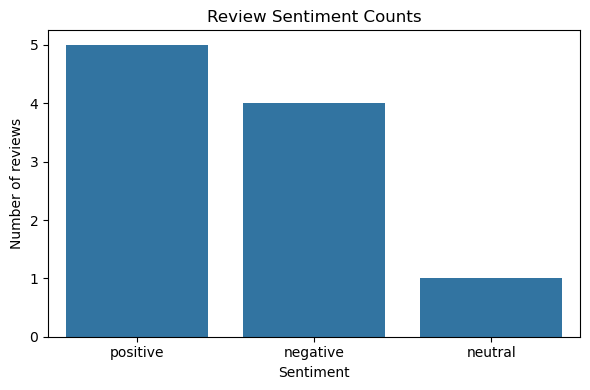

In [3]:
print("Columns:", df.columns.tolist())
print("\\nMissing values:")
print(df.isnull().sum())
print("\\nSentiment counts:")
print(df["sentiment"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment")
plt.title("Review Sentiment Counts")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

## 4. Clean the review text

In [4]:


def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)       
    text = text.lower()
    text = re.sub(r"[^a-z\\s]", " ", text)    
    text = re.sub(r"\\s+", " ", text).strip()  
    return text

df["clean_review"] = df["review_text"].apply(clean_text)
display(df[["review_text", "clean_review", "sentiment"]].head())

,review_text,clean_review,sentiment
0,"The product quality is exceptional, exceeded a...",the product quality is exceptional exceeded a...,positive
1,Terrible customer service and the item arrived...,terrible customer service and the item arrived...,negative
2,"Average performance, decent for the price poin...",average performance decent for the price poin...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love this easy to setup robust a...,positive
4,Stopped working after two days. Extremely disa...,stopped working after two days extremely disa...,negative


## 5. Prepare positive and negative labels

In [5]:

binary_df = df[df["sentiment"].isin(["positive", "negative"])].copy()

X = binary_df["clean_review"]
y = binary_df["sentiment"]

print("Binary dataset size:", len(binary_df))
print(y.value_counts())

Binary dataset size: 9
sentiment
positive    5
negative    4
Name: count, dtype: int64


## 6. Split data into training and testing sets

In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

Train samples: 6
Test samples: 3


## 7. TF-IDF feature extraction

In [7]:

tfidf = TfidfVectorizer(max_features=5000, stop_words="english")

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF training matrix shape:", X_train_tfidf.shape)
print("TF-IDF testing matrix shape:", X_test_tfidf.shape)

TF-IDF training matrix shape: (6, 36)
TF-IDF testing matrix shape: (3, 36)


## 8. Train Multinomial Naive Bayes and Logistic Regression

In [10]:

X_test_tfidf = tfidf.transform(X_test)


nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)

print("Models trained successfully!")

Models trained successfully!


## 9. Compare model accuracy

In [11]:
model_results = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, lr_pred)
    ]
}).sort_values("Accuracy", ascending=False)

display(model_results)
print("Note: Test accuracy is highly uncertain because this dataset is very small.")

,Model,Accuracy
0,Multinomial Naive Bayes,0.666667
1,Logistic Regression,0.666667


Note: Test accuracy is highly uncertain because this dataset is very small.


## 10. Classification reports

In [13]:
print("MULTINOMIAL NAIVE BAYES")
print(classification_report(y_test, nb_pred, zero_division=0))

print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred, zero_division=0))

MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67         1
    positive       1.00      0.50      0.67         2

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.67      1.00      0.80         2

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



## 11. Confusion matrix

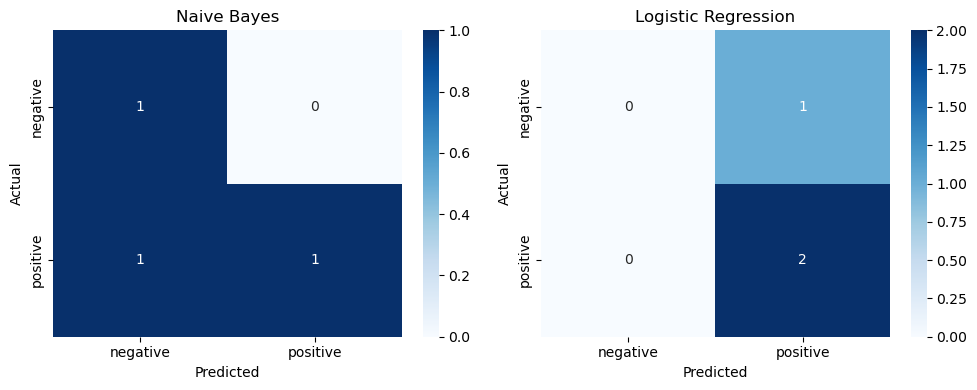

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, model_name, predictions in [
    (axes[0], "Naive Bayes", nb_pred),
    (axes[1], "Logistic Regression", lr_pred)
]:
    cm = confusion_matrix(y_test, predictions, labels=["negative", "positive"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["negative", "positive"],
                yticklabels=["negative", "positive"], ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 12. Fit final model using all binary reviews

In [15]:

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, stop_words="english")),
    ("classifier", MultinomialNB())
])
final_model.fit(X, y)

print("Final prediction pipeline is fitted on all positive/negative reviews.")

Final prediction pipeline is fitted on all positive/negative reviews.


## 13. Test the classifier with your own review

In [16]:
def predict_sentiment(review):
    """Return predicted polarity and confidence for one review string."""
    prediction = final_model.predict([review])[0]
    probabilities = final_model.predict_proba([review])[0]
    confidence = float(probabilities.max())
    print("Review:", review)
    print("Predicted sentiment:", prediction.upper())
    print(f"Model confidence: {confidence:.2%}")
    return prediction, confidence

# Try changing the sample text:
predict_sentiment("The product is excellent and works perfectly. I love it!")

Review: The product is excellent and works perfectly. I love it!
Predicted sentiment: POSITIVE
Model confidence: 67.78%


(np.str_('positive'), 0.6778449343761109)

## 14. Try a few sample reviews

In [17]:
sample_reviews = [
    "This is terrible and I am very disappointed.",
    "Amazing quality, I would buy this again.",
    "The service was not good and delivery was late."
]

for review in sample_reviews:
    predict_sentiment(review)
    print("-" * 50)

Review: This is terrible and I am very disappointed.
Predicted sentiment: NEGATIVE
Model confidence: 57.73%
--------------------------------------------------
Review: Amazing quality, I would buy this again.
Predicted sentiment: POSITIVE
Model confidence: 63.47%
--------------------------------------------------
Review: The service was not good and delivery was late.
Predicted sentiment: NEGATIVE
Model confidence: 57.60%
--------------------------------------------------
